### IPD441 - Visión por Computador
# Clase 10: Vision Transformers 
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Transformers

<div align="right">
    <img src="img/Transformer.jpg" alt="" width="20%" align="right" />
</div>

La arquitectura del Transformer fue introducida en el año 2017 por Vaswani et al. en el artículo ["Attention is All You Need"](https://arxiv.org/pdf/1706.03762.pdf) y revolucionó el campo del NLP. Sin embargo, en CV su incorporación no fue inmediata debido a problemas de escalabilidad. Recién en 2020 con [“An Image Is Worth 16×16 Words: transformers For Image Recognition At Scale”](https://arxiv.org/pdf/2010.11929.pdf) comienzan a masificarse los modelos Vision Transformers (ViT).

# Attention

En NLP, la atención permite considerar el contexto de las palabras y centrar la atención en las relaciones clave entre diferentes tokens. En tanto en CV, la atención se dirige hacia las características visuales relevantes de una imagen, permitiendo identificar patrones, objetos y detalles significativos en una escena.

<div align="center">
    <img src="img/attention.png" alt="" width="50%" align="center" />
</div>

## Alignment

La atención compara vectores de palabras y calcula una "alineación" que describe su similaridad en función de su significado semántico y contextual.

<div align="center">
    <img src="img/alignment.png" alt="" width="30%" align="center" />
</div>

## Encoder

Un codificador con capas de atención puede agregar significado contextual a las incrustaciones.

<div align="center">
    <img src="img/encoder.png" alt="" width="80%" align="center" />
</div>

## Transformer encoder 

El codificador del Transformer crea embeddings de tokens de palabras antes de pasarlas a un "cabezal" específico de la tarea.

<div align="center">
    <img src="img/transformer_encoder.png" alt="" width="75%" align="center" />
</div>

## Visual transformer encoder 

El codificador del Visual Transformer funciona de manera similar, pero en lugar de consumir tokens de palabras, recibe parches de imágenes.

<div align="center">
    <img src="img/transformer_encoder_patches.png" alt="" width="100%" align="center" />
</div>

### Visual transformer encoder process

<div align="right">
    <img src="img/visual-transformer-encoder.png" alt="" width="20%" align="right" />
</div>

• Divide la imagen en parches y los convierte en vectores numéricos para representar regiones específicas de la imagen. 

• Aplica normalización para estandarizar y mejorar el flujo de datos dentro de cada capa del modelo. 

• La Capa "Multi-Head Attention" evalúa las relaciones entre los parches de la imagen, permitiendo al modelo comprender las dependencias y conexiones entre diferentes partes de la imagen. 

• Añade información sobre la posición de cada parche en la cuadrícula de la imagen, permitiendo al modelo entender la disposición espacial de los elementos dentro de la imagen. 

• Finalmente, un MLP procesa y transforma las representaciones de los parches, capturando características complejas de la imagen. 

# Vision Transformer

<div align="center">
    <img src="img/vit_input.png" alt="" width="100%" align="center" />
</div>

In [1]:
# !pip install timm

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import PIL

import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

from timm import create_model

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device = ", device)

device =  cpu


In [4]:
model = create_model("vit_base_patch16_224", pretrained=True).to(device)

In [5]:
IMG_SIZE = (224, 224)
NORMALIZE_MEAN = (0.5, 0.5, 0.5)
NORMALIZE_STD = (0.5, 0.5, 0.5)
transforms = [
              T.Resize(IMG_SIZE),
              T.ToTensor(),
              T.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
              ]

transforms = T.Compose(transforms)

In [6]:
imagenet_labels = dict(enumerate(open('ilsvrc2012_wordnet_lemmas.txt')))
img = PIL.Image.open('img/santorini.png')
img_tensor = transforms(img).unsqueeze(0).to(device)
output = model(img_tensor)

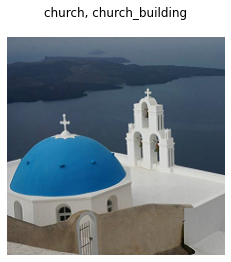

In [7]:
plt.imshow(img)
plt.title(imagenet_labels[int(torch.argmax(output))])
plt.axis('off')
plt.show()

# 1. Split Image into Patches

La imagen de entrada se divide en N parches (N = 14 x 14 for ViT-Base) y se convierte en embeddings de dimensión D=768 usando una convolución 2D:
```
Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
```

In [8]:
patches = model.patch_embed(img_tensor)  # patch embedding convolution
print("Image tensor: ", img_tensor.shape)
print("Patch embeddings: ", patches.shape)

Image tensor:  torch.Size([1, 3, 224, 224])
Patch embeddings:  torch.Size([1, 196, 768])


In [9]:
def split_image_into_patches(img):
    fig = plt.figure(figsize=(8, 8))
    fig.suptitle("Visualization of Patches", fontsize=24)
    img = np.asarray(img)

    for i in range(0, 196):
        x = i % 14
        y = i // 14
        patch = img[y * 16:(y + 1) * 16, x * 16:(x + 1) * 16]
        ax = fig.add_subplot(14, 14, i + 1)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.imshow(patch)

    plt.show()

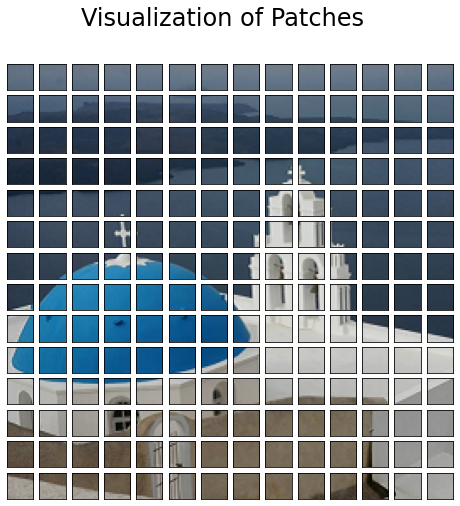

In [10]:
split_image_into_patches(img)

## Dimensiones de los parches

Conversión de una imagen de 224x224 píxeles en 256 parches de imagen de 14x14 píxeles.

<div align="center">
    <img src="img/patches_shapes.png" alt="" width="70%" align="center" />
</div>

## Linear Projection

Después de crear los parches de imagen, se utiliza una capa de proyección lineal para asignar las "matrices" de parches de imagen a los "vectores" de incrustación de parches.

<div align="center">
    <img src="img/linear_projection.png" alt="" width="60%" align="center" />
</div>

## El token CLS

Una característica introducida en los Transformers con BERT fue el uso de un token [CLS] (o “clasificación”). El token [CLS] era un "token especial" que se anteponía a cada oración ingresada en BERT y actuaba como  agregador de información global sobre la secuencia de entrada.

<div align="center">
    <img src="img/CLS_BERT.png" alt="" width="50%" align="center" />
</div>

## Learnable Embeddings

ViT aplica la misma lógica del token [CLS] al agregar una "incrustación que se puede aprender". Esta incrustación que se puede aprender es la misma que el token [CLS] utilizado por BERT.

<div align="center">
    <img src="img/CLS.png" alt="" width="80%" align="center" />
</div>

# 2. Add Position Embeddings

Los Transformers no tienen ningún mecanismo predeterminado que considere el "orden" de los embeddings de tokens o parches. Sin embargo, el orden es esencial. En el lenguaje, el orden de las palabras puede cambiar completamente su significado. Lo mismo ocurre con las imágenes. Si se le presenta un juego de rompecabezas desordenado, es difícil o imposible para una persona predecir con precisión lo que representa el rompecabezas completo.

Para que los parches tengan en cuenta la posición, se agregan vectores de "position embedding" que aprenden la distancia de cada parche dentro de la imagen.

In [11]:
pos_embed = model.pos_embed
print(pos_embed.shape)

torch.Size([1, 197, 768])


In [12]:
def position_embeddings(pos_embed):
    cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
    fig = plt.figure(figsize=(8, 8))
    fig.suptitle("Visualization of position embedding similarities", fontsize=24)
    for i in range(1, pos_embed.shape[1]):
        sim = F.cosine_similarity(pos_embed[0, i:i+1], pos_embed[0, 1:], dim=1)
        sim = sim.reshape((14, 14)).detach().cpu().numpy()
        ax = fig.add_subplot(14, 14, i)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.imshow(sim)

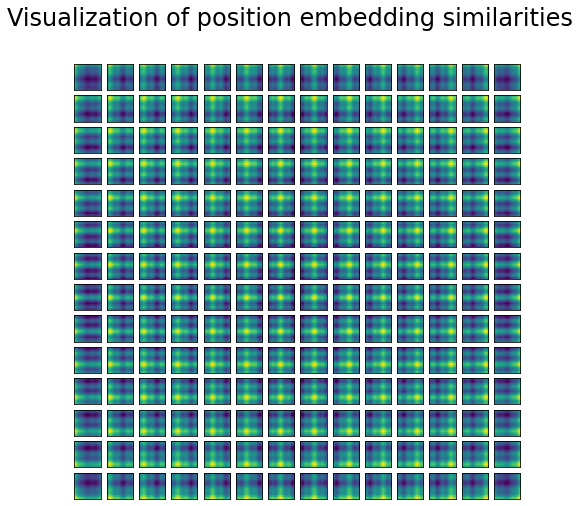

In [13]:
position_embeddings(pos_embed)

### Make Transformer Input

Un token de clase que se puede aprender se antepone a los vectores de incrustación del parche como el vector 0.
Se agregan 197 (1 + 14 x 14) vectores de incrustación de posición que se pueden aprender a los vectores de incrustación de parches.

In [14]:
transformer_input = torch.cat((model.cls_token, patches), dim=1) + pos_embed
print("Transformer input: ", transformer_input.shape)

Transformer input:  torch.Size([1, 197, 768])


# 3. ViT Encoder

<div align="center">
    <img src="img/vit_transformer_encoder.png" alt="" width="80%" align="center" />
</div>


### Series Transformer Encoders

In [15]:
print("Input tensor to Transformer (z0): ", transformer_input.shape)
x = transformer_input.clone()
for i, blk in enumerate(model.blocks):
    print("Entering the Transformer Encoder {}".format(i))
    x = blk(x)
x = model.norm(x)
transformer_output = x[:, 0]
print("Output vector from Transformer (z12-0):", transformer_output.shape)

Input tensor to Transformer (z0):  torch.Size([1, 197, 768])
Entering the Transformer Encoder 0
Entering the Transformer Encoder 1
Entering the Transformer Encoder 2
Entering the Transformer Encoder 3
Entering the Transformer Encoder 4
Entering the Transformer Encoder 5
Entering the Transformer Encoder 6
Entering the Transformer Encoder 7
Entering the Transformer Encoder 8
Entering the Transformer Encoder 9
Entering the Transformer Encoder 10
Entering the Transformer Encoder 11
Output vector from Transformer (z12-0): torch.Size([1, 768])


## How Attention Works

In [16]:
print("Transformer Multi-head Attention block:")
attention = model.blocks[0].attn
print(attention)
print("input of the transformer encoder:", transformer_input.shape)

Transformer Multi-head Attention block:
Attention(
  (qkv): Linear(in_features=768, out_features=2304, bias=True)
  (q_norm): Identity()
  (k_norm): Identity()
  (attn_drop): Dropout(p=0.0, inplace=False)
  (proj): Linear(in_features=768, out_features=768, bias=True)
  (proj_drop): Dropout(p=0.0, inplace=False)
)
input of the transformer encoder: torch.Size([1, 197, 768])


In [17]:
# fc layer to expand the dimension
transformer_input_expanded = attention.qkv(transformer_input)[0]
print("expanded to: ", transformer_input_expanded.shape)

expanded to:  torch.Size([197, 2304])


In [18]:
# Split qkv into mulitple q, k, and v vectors for multi-head attention
qkv = transformer_input_expanded.reshape(197, 3, 12, 64)  # (N=197, (qkv), H=12, D/H=64)
print("split qkv : ", qkv.shape)
q = qkv[:, 0].permute(1, 0, 2)  # (H=12, N=197, D/H=64)
k = qkv[:, 1].permute(1, 0, 2)  # (H=12, N=197, D/H=64)
kT = k.permute(0, 2, 1)  # (H=12, D/H=64, N=197)
print("transposed ks: ", kT.shape)

split qkv :  torch.Size([197, 3, 12, 64])
transposed ks:  torch.Size([12, 64, 197])


attention matrix:  torch.Size([12, 197, 197])


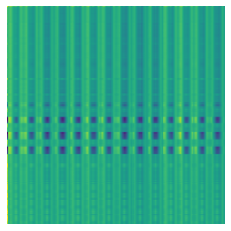

In [19]:
# Attention Matrix
attention_matrix = q @ kT
print("attention matrix: ", attention_matrix.shape)
plt.imshow(attention_matrix[3].detach().cpu().numpy())
plt.axis('off')
plt.show()

In [20]:
def visualization_attention(img, attention_matrix):
    fig = plt.figure(figsize=(16, 8))
    fig.suptitle("Visualization of Attention", fontsize=24)
    img = np.asarray(img)
    m,n = attention_matrix.shape[:2]
    ax = fig.add_subplot(3, 4, 1)
    ax.imshow(img)
    ax.axis('off')
    for i in range(m-1):
        attn_heatmap = attention_matrix[i, n-1, 1:].reshape((14, 14)).detach().cpu().numpy()
        ax = fig.add_subplot(3, 4, i + 2)
        ax.axis('off')
        ax.imshow(attn_heatmap)

    plt.show()

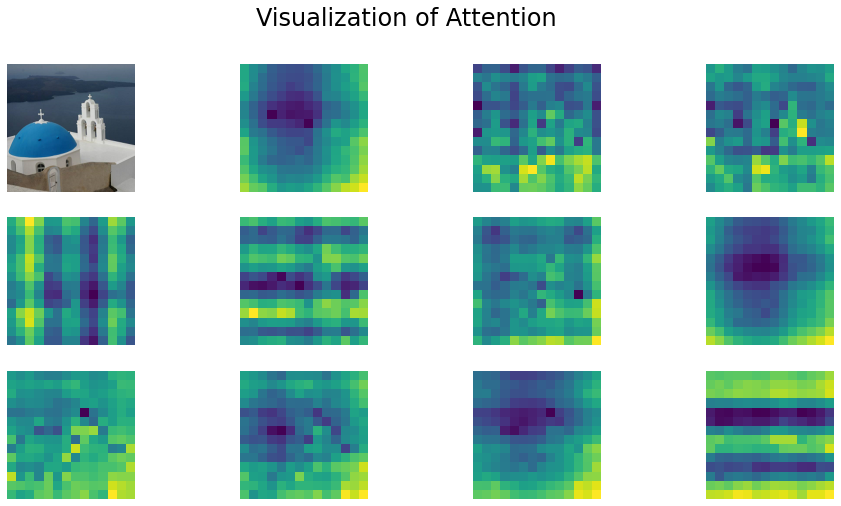

In [21]:
visualization_attention(img, attention_matrix)

# 4. MLP (Classification) Head

En la etapa final, un MLP recibe el vector de salida del transformer y entrega el resultado de la clasificación.

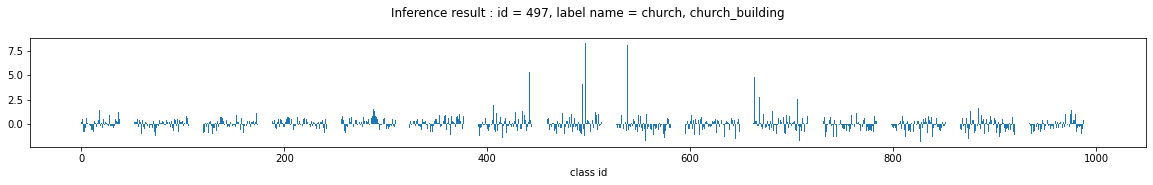

In [28]:
result = model.head(transformer_output)
result_label_id = int(torch.argmax(result))
plt.figure(figsize=(20, 2))
plt.bar(x=range(1000), height=result.detach().cpu().numpy()[0])
plt.xlabel("class id")
plt.title("Inference result : id = {}, label name = {}".format(result_label_id, imagenet_labels[result_label_id]))
plt.show()

# Self-Supervised Vision Transformers with DINO

DINO es un método de aprendizaje autosupervisado para el entrenamiento de Vision Transformers. En este caso, el modelo se enseña a sí mismo mediante la exploración y análisis de los datos sin depender completamente de información externa proporcionada por etiquetas.

<video controls src="img/DINO.mp4" width="50%"/>

## Distillation

La destilación del conocimiento es un proceso en el cual se entrena un modelo más pequeño, llamado "modelo estudiante", para aprender de un modelo más grande y complejo, denominado "modelo maestro". El objetivo es transferir el conocimiento del modelo maestro al modelo estudiante de manera más eficiente y con menos requisitos computacionales.

<div align="center">
    <img src="img/distillation.png" alt="" width="50%" align="center" />
</div>

## Self-distillation

DINO utiliza Vision Transformers (ViT) y emplea autodestilación, donde un modelo de estudiante aprende alineando sus resultados con un modelo de maestro actualizado dinámicamente. Este enfoque conduce a la aparición de prototipos visuales sin necesidad de datos etiquetados.

<div align="center">
    <img src="img/selfdistillation1.png" alt="" width="50%" align="left" />
    <img src="img/selfdistillation2.png" alt="" width="50%" align="center" />
</div>

# Self-attention visualization

Permite ver la autoatención del token [CLS] en los diferentes cabezales de la última capa.

In [ ]:
%cd dino/

In [30]:
from dino.visualize_attention import *

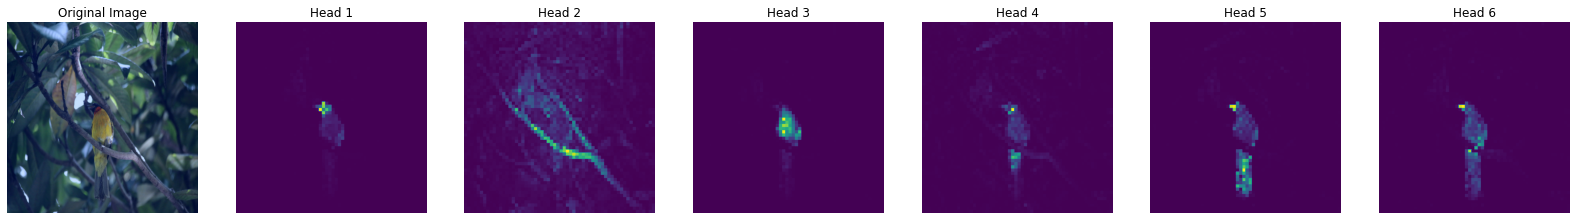

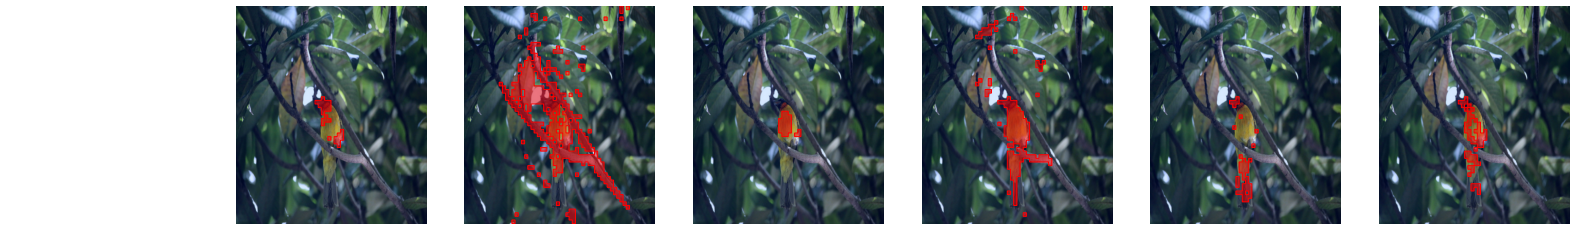

In [31]:
vis_attention("../test/bird.png", threshold=0.5)

# Self-attention video generation

In [3]:
%%HTML
<video width="50%" controls>
  <source src="input/dog.mp4" type="video/mp4">
</video>

In [6]:
cd ..

/Users/nicolastorres/Jupyter Notebooks/2024-1/IPD-441 Visión por Computador/Clase 9


In [ ]:
!python video_generation.py \
--pretrained_weights ../dino_deitsmall8_pretrain.pth \
--input_path ../input/dog.mp4 \
--output_path ../output/dog/ \
--resize 512

In [4]:
def plot_attention_frames(frame_folder_path, folder_path, num_columns):
    
    # Get the list of frames
    frame_files = sorted([f for f in os.listdir(frame_folder_path) 
                          if f.startswith("frame")])[:num_columns]
    
    # Calculate the number of columns
    num_images = len(frame_files)

    # Create subplots
    fig, axes = plt.subplots(2, num_columns, figsize=(15, 5))

    for i, frame_file in enumerate(frame_files):
        image_path = os.path.join(frame_folder_path, frame_file)
        ax = axes[0, i]
        img = PIL.Image.open(image_path)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(frame_file)
        
    # Get the list of attention images
    image_files = sorted([f for f in os.listdir(folder_path) 
                          if f.startswith("attn-frame")])[:num_columns]
    
    # Plot attention images
    for i, image_file in enumerate(image_files):
        image_path = os.path.join(folder_path, image_file)
        ax = axes[1, i]
        img = PIL.Image.open(image_path)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(image_file)

    plt.tight_layout()
    plt.show()

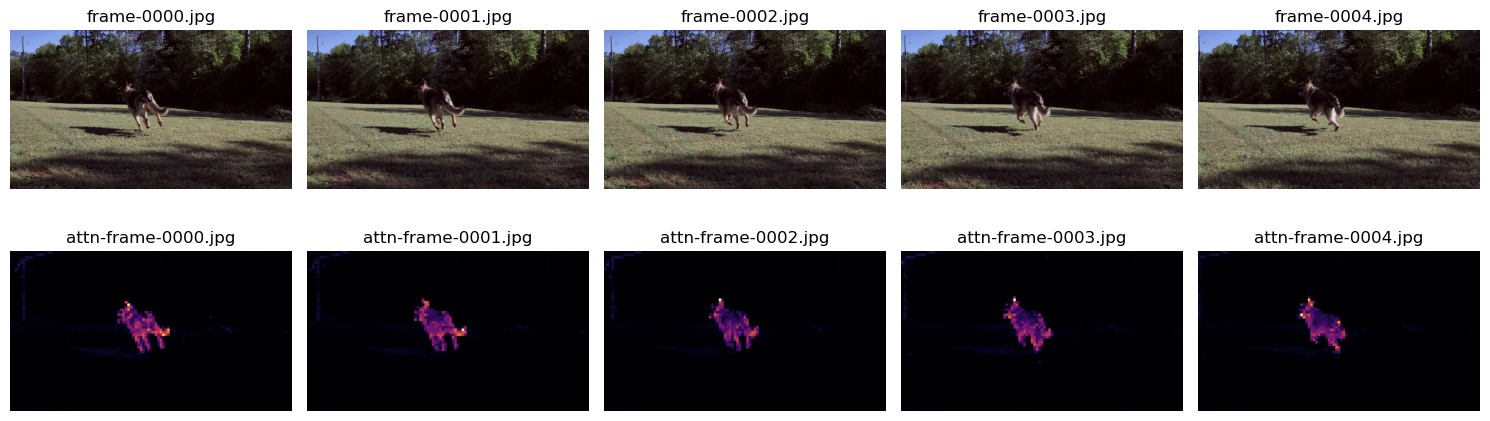

In [5]:
plot_attention_frames("output/dog/frames", "output/dog/attention", num_columns=5)

In [6]:
%%HTML
<video width="100%" controls>
  <source src="img/dog.mp4" type="video/mp4">
</video>